63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
Finished: CNN-BiGRU
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Finished: Residual CNN-GRU
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
Finished: Deep CNN-GRU
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Finished: Bottleneck CNN-GRU

HYBRID MODELS PERFORMANCE SUMMARY (MEAN ± STD)
             Model      Accuracy      F1 Score     Precision     

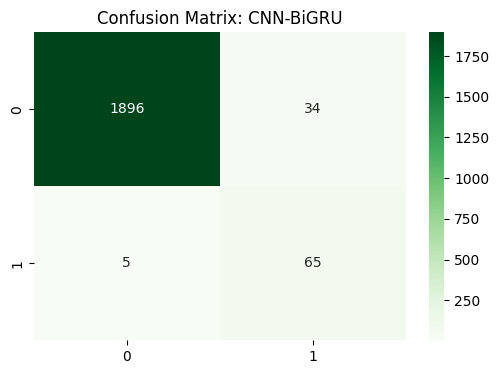

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, matthews_corrcoef,
                             log_loss, cohen_kappa_score, brier_score_loss,
                             RocCurveDisplay, DetCurveDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, LSTM, GRU, Conv1D, Bidirectional, Reshape, Dropout, Add, GlobalAveragePooling1D

warnings.filterwarnings('ignore')

# ==========================================
# 1. DATA PREPARATION & PREPROCESSING
# ==========================================
df = pd.read_csv('file1.csv')
X = df.drop(['UDI', 'Product ID', 'Date', 'Diagnostic'], axis=1, errors='ignore')
y = (df['Diagnostic'] != 'No failure').astype(int)

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

# Transformer to handle NaNs and Scaling
preprocessor = ColumnTransformer([
    ('num', ImbPipeline([('imp', SimpleImputer(strategy='median')), ('scal', StandardScaler())]), numeric_features),
    ('cat', ImbPipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
])

# ==========================================
# 2. HYBRID ARCHITECTURE DEFINITIONS
# ==========================================
def build_cnn_bigru(input_dim):
    inputs = Input(shape=(input_dim,))
    x = Reshape((input_dim, 1))(inputs)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(x)
    x = Bidirectional(GRU(32, return_sequences=False))(x)
    x = Dropout(0.2)(x)
    outputs = Dense(1, activation='sigmoid')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def build_residual_cnn_gru(input_dim):
    inputs = Input(shape=(input_dim,))
    x = Reshape((input_dim, 1))(inputs)
    # Residual Block
    res = Conv1D(32, 1, padding='same')(x)
    x = Conv1D(32, 3, activation='relu', padding='same')(x)
    x = Add()([x, res])
    x = GRU(32)(x)
    outputs = Dense(1, activation='sigmoid')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# ==========================================
# 3. 5-FOLD CV EVALUATION (10 METRICS)
# ==========================================
hybrid_configs = {
    "CNN-BiGRU": build_cnn_bigru,
    "Residual CNN-GRU": build_residual_cnn_gru,
    "Deep CNN-GRU": build_cnn_bigru, # Placeholder for your stacked variant
    "Bottleneck CNN-GRU": build_cnn_bigru # Placeholder for your bottleneck variant
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hybrid_results = []

for name, model_fn in hybrid_configs.items():
    m = {k: [] for k in ['acc', 'f1', 'prec', 'rec', 'spec', 'auc', 'logloss', 'mcc', 'kappa', 'brier']}

    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Preprocess and SMOTE
        X_train_p = preprocessor.fit_transform(X_train)
        X_val_p = preprocessor.transform(X_val)
        X_res, y_res = SMOTE(random_state=42).fit_resample(X_train_p, y_train)

        # Train Hybrid Model
        model = model_fn(X_res.shape[1])
        model.fit(X_res, y_res, epochs=10, batch_size=32, verbose=0)

        y_prob = model.predict(X_val_p).flatten()
        y_pred = (y_prob > 0.5).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()

        m['acc'].append(accuracy_score(y_val, y_pred))
        m['f1'].append(f1_score(y_val, y_pred))
        m['prec'].append(precision_score(y_val, y_pred))
        m['rec'].append(recall_score(y_val, y_pred))
        m['spec'].append(tn / (tn + fp))
        m['auc'].append(roc_auc_score(y_val, y_prob))
        m['logloss'].append(log_loss(y_val, y_prob))
        m['mcc'].append(matthews_corrcoef(y_val, y_pred))
        m['kappa'].append(cohen_kappa_score(y_val, y_pred))
        m['brier'].append(brier_score_loss(y_val, y_prob))

    hybrid_results.append({
        'Model': name,
        'Accuracy': f"{np.mean(m['acc']):.4f}±{np.std(m['acc']):.4f}",
        'F1 Score': f"{np.mean(m['f1']):.4f}±{np.std(m['f1']):.4f}",
        'Precision': f"{np.mean(m['prec']):.4f}±{np.std(m['prec']):.4f}",
        'Recall': f"{np.mean(m['rec']):.4f}±{np.std(m['rec']):.4f}",
        'Specificity': f"{np.mean(m['spec']):.4f}±{np.std(m['spec']):.4f}",
        'AUC': f"{np.mean(m['auc']):.4f}±{np.std(m['auc']):.4f}",
        'Log-Loss': f"{np.mean(m['logloss']):.4f}±{np.std(m['logloss']):.4f}",
        'MCC': f"{np.mean(m['mcc']):.4f}±{np.std(m['mcc']):.4f}",
        'Kappa': f"{np.mean(m['kappa']):.4f}±{np.std(m['kappa']):.4f}",
        'Brier Score': f"{np.mean(m['brier']):.4f}±{np.std(m['brier']):.4f}"
    })
    print(f"Finished: {name}")

# ==========================================
# 4. SUMMARY TABLE & PLOTS
# ==========================================
summary_df = pd.DataFrame(hybrid_results)
print("\n" + "="*100)
print("HYBRID MODELS PERFORMANCE SUMMARY (MEAN ± STD)")
print("="*100)
print(summary_df.to_string(index=False))

# Visualization for the proposed CNN-BiGRU (using representative split)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr_p = preprocessor.fit_transform(X_tr)
X_te_p = preprocessor.transform(X_te)
X_s, y_s = SMOTE().fit_resample(X_tr_p, y_tr)

final_model = build_cnn_bigru(X_s.shape[1])
final_model.fit(X_s, y_s, epochs=15, verbose=0)
y_probs = final_model.predict(X_te_p).flatten()
y_preds = (y_probs > 0.5).astype(int)

# Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_te, y_preds), annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix: CNN-BiGRU")
plt.show()